# Fine-Tuning de LLMs para Text-to-SQL: Do Dado Sintético à Avaliação Funcional
### Arquitetura: **Qwen2.5-Coder-7B** com **LoRA (PEFT)** 

Este notebook é um treinamento de uma LLM local para um caso de uso de engenharia de software de altíssimo impacto no mercado: **Text-to-SQL**.

O objetivo é ensinar uma LLM a receber o **esquema de um banco de dados relacional** e uma **pergunta em linguagem natural (Português)** com jargões corporativos específicos da empresa e gerar uma **consulta SQL sintática e semanticamente válida**.

---

### Por que o Qwen2.5-Coder-7B?

| Característica | SmolLM2-135M (Utilizado em aula) | Qwen2.5-Coder-7B (Este Notebook) |
| :--- | :--- | :--- |
| **Parâmetros** | ~135 Milhões | **~7.61 Bilhões** (~56x maior!) |
| **Especialização** | Modelo geral compacto | Treinado em mais de 5.5 trilhões de tokens de código e SQL |
| **Contexto Máximo** | 2.048 tokens | Até 32.768 tokens |
| **VRAM Necessária (bfloat16)** | < 1 GB | ~15 GB (pesos) + ~5 GB (treino LoRA) = **~20 GB** |

---

### Roteiro do Pipeline Completo

1. **Setup e Diagnóstico de Hardware**: Detecção de VRAM, GPU/dispositivo e inicialização do modelo em precisão `bfloat16`/`float16`.
2. **Carregando o Modelo (Qwen2.5-Coder-7B)**: Carregamento do tokenizer e do modelo base especializado em código e SQL.
3. **O Banco de Dados Relacional (SQLite em Memória)**: Criação das tabelas relacionais (`clientes`, `produtos`, `pedidos`, `itens_pedido`) com dados sintéticos reais.
4. **Engenharia de Dados Sintéticos e Validação Funcional Automática**:
   - Geração sintética de enunciados e queries SQL com validação funcional automática no SQLite.
   - Divisão em **Variação** (paráfrases intra-distribuição) e **Inéditas** (regras fora da distribuição para teste zero-shot).
5. **Avaliação Funcional Baseline (Antes do Treinamento)**: Medição da acurácia de execução (*Execution Accuracy / pass@1*) do modelo base no SQLite.
6. **Configurando LoRA (Low-Rank Adaptation)**: Adaptação de baixo rank para fine-tuning eficiente e rápido com economia de VRAM.
7. **Laço de Treino PyTorch com Mascaramento de Prompt**: Forward pass, mascaramento de prompt com labels `-100` (otimizando apenas o SQL alvo), cálculo de loss e retropropagação.
8. **Curva de Aprendizado (Loss de Treino vs. Validação)**: Gráfico comparativo da evolução do loss de treino vs teste com `matplotlib`.
9. **Avaliação Pós-Treino e Placar Comparativo (Antes vs. Depois)**: Reavaliação no conjunto de teste e comprovação estatística do ganho de acurácia (*Antes x Depois*).
10. **Visualização do Banco de Dados Fictício**: Inspeção dos registros e estrutura das tabelas usando DataFrames do `pandas`.
11. **Testando Respostas do Modelo Text-to-SQL**: Testes interativos em tempo real via terminal e interface gráfica web com Gradio.


In [1]:
# Instalação das bibliotecas necessárias via requirements.txt
!pip install -q -r requirements.txt
# Caso execute em ambiente sem o requirements.txt, descomente a linha abaixo:
# !pip install -q torch transformers accelerate peft datasets matplotlib tabulate pandas gradio


In [2]:
# Bibliotecas padrão do Python
import os
import sys
import gc
import json
import random
import time
import sqlite3
from pathlib import Path

# Manipulação e visualização de dados
import pandas as pd
import matplotlib.pyplot as plt
from tabulate import tabulate

# Deep Learning e Fine-Tuning com LoRA
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model, TaskType

# Interface interativa Web
import gradio as gr

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Setup e Diagnóstico de Hardware (Detecção de VRAM)

Com hardware disponível podemos treinar o modelo de 7B em precisão de 16 bits (`bfloat16` ou `float16`), mantendo máxima fidelidade matemática. O código abaixo detecta o dispositivo e reporta a memória de vídeo disponível (no caso da CUDA).


In [ ]:
# ==============================================================================
# ⚙️ CONFIGURAÇÃO DE REPRODUTIBILIDADE E DETECÇÃO DE HARDWARE
# ==============================================================================
# Fixando sementes para reprodutibilidade total
random.seed(42)
torch.manual_seed(42)

# Detecção de Hardware
if torch.cuda.is_available():
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    print(f"✅ GPU Detectada: {gpu_name}")
    print(f"📦 VRAM Total: {vram_gb:.1f} GB")
    print(f"⚡ Tipo de Precisão: {compute_dtype}")
elif torch.backends.mps.is_available():
    device = "mps"
    compute_dtype = torch.float16
    print("✅ Apple Silicon Detectado (MPS Ativo)")
else:
    device = "cpu"
    compute_dtype = torch.float16
    print("⚠️ Rodando em CPU (Modo de fallback)")


✅ Apple Silicon Detectado (MPS Ativo)


## 2. Carregando o Modelo: Qwen2.5-Coder-7B

O **Qwen2.5-Coder-7B** é um dos modelos abertos de código mais avançados do mundo. Ele é ideal para Text-to-SQL por compreender estruturas sintáticas complexas, nomes de colunas e regras relacionais.


In [4]:
MODELO_ID = "Qwen/Qwen2.5-Coder-7B"   # Modelo Base de 7.6B parâmetros

print(f"Baixando e carregando tokenizador e modelo: {MODELO_ID}...")
tokenizer = AutoTokenizer.from_pretrained(MODELO_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Carrega os pesos do modelo no dispositivo selecionado com precisão de 16 bits
model = AutoModelForCausalLM.from_pretrained(
    MODELO_ID,
    torch_dtype=compute_dtype,
    device_map=device if device == "cuda" else None,
    trust_remote_code=True
)
if device != "cuda":
    model = model.to(device)

model.eval()

# Anatomia do Modelo
total_params = sum(p.numel() for p in model.parameters())
cfg = model.config
print("=" * 50)
print(f"ANATOMIA DO MODELO: {MODELO_ID}")
print(f"Total de parâmetros:     {total_params:,}".replace(",", "."))
print(f"Camadas (Transformer):   {cfg.num_hidden_layers}")
print(f"Dimensão de Embedding:   {cfg.hidden_size}")
print(f"Cabeças de Atenção:      {cfg.num_attention_heads}")
print(f"Tamanho do Vocabulário:  {cfg.vocab_size:,}".replace(",", "."))
print("=" * 50)


Baixando e carregando tokenizador e modelo: Qwen/Qwen2.5-Coder-7B...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 339/339 [00:05<00:00, 62.22it/s]


ANATOMIA DO MODELO: Qwen/Qwen2.5-Coder-7B
Total de parâmetros:     7.615.616.512
Camadas (Transformer):   28
Dimensão de Embedding:   3584
Cabeças de Atenção:      28
Tamanho do Vocabulário:  152.064


## 3. O Banco de Dados Relacional (SQLite em Memória)

Para ensinar e testar consultas SQL com **verificação funcional objetiva**, criamos um banco de dados SQLite com um esquema clássico de E-Commerce/Vendas:
- `clientes`: Informações cadastrais e localização.
- `produtos`: Itens disponíveis, categorias, preços e estoque.
- `pedidos`: Compras efetuadas com status e valor total.
- `itens_pedido`: Relação n:n com quantidade e preço praticado.


In [5]:
def criar_banco_dados():
    """Cria um banco SQLite em memória com dados mockados determinísticos."""
    conn = sqlite3.connect(":memory:")
    cur = conn.cursor()

    # Esquema das tabelas
    cur.executescript("""
    CREATE TABLE clientes (
        id INTEGER PRIMARY KEY,
        nome TEXT NOT NULL,
        cidade TEXT NOT NULL,
        estado TEXT NOT NULL,
        idade INTEGER NOT NULL,
        data_cadastro TEXT NOT NULL
    );

    CREATE TABLE produtos (
        id INTEGER PRIMARY KEY,
        nome TEXT NOT NULL,
        categoria TEXT NOT NULL,
        preco REAL NOT NULL,
        estoque INTEGER NOT NULL
    );

    CREATE TABLE pedidos (
        id INTEGER PRIMARY KEY,
        cliente_id INTEGER NOT NULL,
        data_pedido TEXT NOT NULL,
        valor_total REAL NOT NULL,
        status TEXT NOT NULL,
        FOREIGN KEY (cliente_id) REFERENCES clientes(id)
    );

    CREATE TABLE itens_pedido (
        id INTEGER PRIMARY KEY,
        pedido_id INTEGER NOT NULL,
        produto_id INTEGER NOT NULL,
        quantidade INTEGER NOT NULL,
        preco_unitario REAL NOT NULL,
        FOREIGN KEY (pedido_id) REFERENCES pedidos(id),
        FOREIGN KEY (produto_id) REFERENCES produtos(id)
    );
    """)

    # Inserção de dados de exemplo
    clientes_dados = [
        (1, 'Ana Silva', 'São Paulo', 'SP', 28, '2023-01-15'),
        (2, 'Bruno Santos', 'Campinas', 'SP', 35, '2023-02-10'),
        (3, 'Carla Oliveira', 'Rio de Janeiro', 'RJ', 42, '2023-03-05'),
        (4, 'Diego Ferreira', 'Belo Horizonte', 'MG', 23, '2023-04-12'),
        (5, 'Eduarda Lima', 'Curitiba', 'PR', 31, '2023-05-20'),
        (6, 'Felipe Rocha', 'São Paulo', 'SP', 45, '2023-06-18'),
        (7, 'Gabriela Souza', 'Niterói', 'RJ', 29, '2023-07-22'),
        (8, 'Henrique Alves', 'Uberlândia', 'MG', 38, '2023-08-30'),
    ]
    cur.executemany("INSERT INTO clientes VALUES (?, ?, ?, ?, ?, ?)", clientes_dados)

    produtos_dados = [
        (1, 'Notebook Pro', 'Eletronicos', 4500.0, 15),
        (2, 'Mouse Sem Fio', 'Eletronicos', 120.0, 50),
        (3, 'Teclado Mecânico', 'Eletronicos', 350.0, 30),
        (4, 'Monitor 27 Pol', 'Eletronicos', 1800.0, 8),
        (5, 'Cadeira Gamer', 'Moveis', 1200.0, 12),
        (6, 'Mesa Escritório', 'Moveis', 850.0, 5),
        (7, 'Livro Python Fluente', 'Livros', 130.0, 40),
        (8, 'Livro Clean Code', 'Livros', 95.0, 25),
        (9, 'Headset Bluetooth', 'Eletronicos', 290.0, 20),
        (10, 'Luminária LED', 'Moveis', 75.0, 60),
    ]
    cur.executemany("INSERT INTO produtos VALUES (?, ?, ?, ?, ?)", produtos_dados)

    pedidos_dados = [
        (101, 1, '2023-09-01', 4620.0, 'concluido'),
        (102, 1, '2023-09-15', 350.0, 'concluido'),
        (103, 2, '2023-09-18', 1200.0, 'concluido'),
        (104, 3, '2023-09-20', 225.0, 'concluido'),
        (105, 4, '2023-09-22', 1800.0, 'pendente'),
        (106, 5, '2023-09-25', 130.0, 'cancelado'),
        (107, 6, '2023-09-28', 4970.0, 'concluido'),
        (108, 7, '2023-10-02', 850.0, 'pendente'),
    ]
    cur.executemany("INSERT INTO pedidos VALUES (?, ?, ?, ?, ?)", pedidos_dados)

    itens_dados = [
        (1, 101, 1, 1, 4500.0),
        (2, 101, 2, 1, 120.0),
        (3, 102, 3, 1, 350.0),
        (4, 103, 5, 1, 1200.0),
        (5, 104, 7, 1, 130.0),
        (6, 104, 8, 1, 95.0),
        (7, 105, 4, 1, 1800.0),
        (8, 106, 7, 1, 130.0),
        (9, 107, 1, 1, 4500.0),
        (10, 107, 3, 1, 350.0),
        (11, 107, 2, 1, 120.0),
        (12, 108, 6, 1, 850.0),
    ]
    cur.executemany("INSERT INTO itens_pedido VALUES (?, ?, ?, ?, ?)", itens_dados)

    conn.commit()
    return conn

# Schema em formato DDL legível que será inserido no prompt do modelo
SCHEMA_PROMPT = """Tabelas disponíveis:
- clientes (id, nome, cidade, estado, idade, data_cadastro)
- produtos (id, nome, categoria, preco, estoque)
- pedidos (id, cliente_id, data_pedido, valor_total, status)
- itens_pedido (id, pedido_id, produto_id, quantidade, preco_unitario)"""

# Teste de execução rápida
conn = criar_banco_dados()
print("✅ Banco SQLite criado com sucesso!")
print(f"Total de clientes: {conn.execute('SELECT COUNT(*) FROM clientes').fetchone()[0]}")
print(f"Total de produtos: {conn.execute('SELECT COUNT(*) FROM produtos').fetchone()[0]}")
print(f"Total de pedidos:  {conn.execute('SELECT COUNT(*) FROM pedidos').fetchone()[0]}")


✅ Banco SQLite criado com sucesso!
Total de clientes: 8
Total de produtos: 10
Total de pedidos:  8


## 4. Engenharia de Dados Sintéticos e Validação Funcional Automática

1. Definimos **famílias de consultas SQL** que cobrem projeção, filtros, agregações (`SUM`, `AVG`, `COUNT`), `JOINs` e ordenação.
2. Criamos **famílias inéditas (`inedita=True`)** como `HAVING`, `CASE WHEN`, subqueries e junções triplas para testar a **generalização fora da distribuição (Zero-Shot)**.
3. Para cada exemplo, executamos o SQL no SQLite e armazenamos o **`resultado_esperado`**. É isso que viabiliza a métrica **Execution Accuracy (EX)**!


In [6]:
FAMILIAS_SQL = {
    # 1. Mapeamento Geográfico: Usuário fala nome do Estado ({1}) -> Banco exige UF ({0})
    "clientes_por_estado": {
        "params": [("SP", "São Paulo"), ("RJ", "Rio de Janeiro"), ("MG", "Minas Gerais"), ("PR", "Paraná")],
        "perguntas": [
            "Liste o nome de todos os clientes do estado de {1}.",
            "Quais são os clientes que moram em {1}?",
            "Mostre os nomes dos clientes localizados no {1}."
        ],
        "sql": "SELECT nome FROM clientes WHERE estado = '{0}';",
    },
    
    # 2. Convenção de Sistema: Usuário usa acento ({1}) -> Banco armazena código ASCII sem acento ({0})
    "produtos_por_categoria": {
        "params": [("Eletronicos", "Eletrônicos"), ("Moveis", "Móveis"), ("Livros", "Livros")],
        "perguntas": [
            "Mostre o nome e o preço de todos os produtos da linha de {1}.",
            "Liste os produtos e seus respectivos preços pertencentes ao setor de {1}.",
            "Quais produtos e preços estão cadastrados no departamento de {1}?"
        ],
        "sql": "SELECT nome, preco FROM produtos WHERE categoria = '{0}';",
    },

    # 3. Conceito de Negócio (Faixas de Preço): Termo comercial ({1}) -> Regra matemática ({0})
    "produtos_acima_preco": {
        "params": [(500.0, "custo elevado"), (1000.0, "linha premium"), (200.0, "ticket médio alto"), (1500.0, "alto luxo")],
        "perguntas": [
            "Quais produtos se enquadram na classificação de {1}?",
            "Liste o nome e preço dos produtos considerados de {1}.",
            "Mostre os produtos e preços que pertencem à faixa de {1}."
        ],
        "sql": "SELECT nome, preco FROM produtos WHERE preco > {0};",
    },

    # 4. Conceito Demográfico: Perfil etário ({1}) -> Filtro de idade ({0})
    "clientes_por_idade": {
        "params": [(30, "perfil adulto"), (35, "perfil sênior"), (40, "perfil executivo master")],
        "perguntas": [
            "Liste nome e idade dos clientes classificados no {1}.",
            "Quais clientes fazem parte da demografia de {1}?",
            "Mostre o nome e a idade dos compradores com {1}."
        ],
        "sql": "SELECT nome, idade FROM clientes WHERE idade > {0};",
    },

    # 5. Jargão Financeiro/ERP: Termo do usuário ({1}) -> Status interno da tabela ({0})
    "contar_pedidos_status": {
        "params": [("concluido", "faturados e pagos"), ("pendente", "em aberto aguardando pagamento"), ("cancelado", "estornados")],
        "perguntas": [
            "Quantos pedidos estão {1}?",
            "Informe a quantidade total de pedidos {1}.",
            "Qual é o número de vendas que constam como {1}?"
        ],
        "sql": "SELECT COUNT(*) FROM pedidos WHERE status = '{0}';",
    },

    "media_preco_categoria": {
        "params": [("Eletronicos", "Eletrônicos"), ("Moveis", "Móveis"), ("Livros", "Livros")],
        "perguntas": [
            "Qual é o preço médio dos itens do setor de {1}?",
            "Calcule a média de preço dos produtos da linha de {1}.",
            "Mostre a média de preços no departamento de {1}."
        ],
        "sql": "SELECT AVG(preco) FROM produtos WHERE categoria = '{0}';",
    },

    "total_faturamento_status": {
        "params": [("concluido", "faturados e pagos"), ("pendente", "em aberto aguardando pagamento")],
        "perguntas": [
            "Qual o valor total somado em pedidos {1}?",
            "Some o valor total de todos os pedidos {1}.",
            "Calcule a receita bruta dos pedidos {1}."
        ],
        "sql": "SELECT SUM(valor_total) FROM pedidos WHERE status = '{0}';",
    },

    "produtos_top_caros": {
        "params": [(3,), (5,), (2,)],
        "perguntas": [
            "Mostre os {0} produtos mais caros da loja ordenados pelo preço decrescente.",
            "Liste os top {0} produtos de maior valor em ordem decrescente.",
            "Quais são os {0} produtos com os maiores preços?"
        ],
        "sql": "SELECT nome, preco FROM produtos ORDER BY preco DESC LIMIT {0};",
    },

    # 6. Regra de Logística/Estoque: Nível de alerta ({1}) -> Limite numérico ({0})
    "estoque_baixo": {
        "params": [(10, "nível crítico de ruptura"), (15, "alerta de reposição"), (20, "estoque de segurança")],
        "perguntas": [
            "Quais produtos estão em {1}?",
            "Liste o nome e o estoque dos produtos que atingiram o {1}.",
            "Mostre o nome e a quantidade dos itens com {1}."
        ],
        "sql": "SELECT nome, estoque FROM produtos WHERE estoque < {0};",
    },

    # 7. Joins com Jargão de Negócio
    "pedidos_com_nome_cliente": {
        "params": [("concluido", "faturados e pagos"), ("pendente", "em aberto aguardando pagamento")],
        "perguntas": [
            "Liste o ID do pedido, o valor total e o nome do cliente para pedidos {1}.",
            "Mostre o número do pedido, seu valor e quem comprou nas vendas {1}.",
            "Traga o id do pedido, valor total e nome do cliente dos pedidos {1}."
        ],
        "sql": "SELECT pedidos.id, pedidos.valor_total, clientes.nome FROM pedidos INNER JOIN clientes ON pedidos.cliente_id = clientes.id WHERE pedidos.status = '{0}';",
    },

    "pedidos_de_um_cliente": {
        "params": [("Ana Silva",), ("Diego Ferreira",), ("Carla Oliveira",)],
        "perguntas": [
            "Liste os pedidos (id, data e valor) realizados pelo cliente '{0}'.",
            "Quais foram os pedidos feitos por '{0}'? Mostre id, data e valor total.",
            "Mostre o histórico de compras de '{0}' contendo id, data_pedido e valor_total."
        ],
        "sql": "SELECT pedidos.id, pedidos.data_pedido, pedidos.valor_total FROM pedidos INNER JOIN clientes ON pedidos.cliente_id = clientes.id WHERE clientes.nome = '{0}';",
    },

    # =========================================================================
    # FAMÍLIAS INÉDITAS (ZERO-SHOT COMPOSICIONAL: SINTAXE NOVA + VOCABULÁRIO APRENDIDO)
    # =========================================================================
    "having_faturamento_cliente": {
        "inedita": True,
        "params": [(1000.0,), (3000.0,)],
        "perguntas": [
            "Liste o ID do cliente e a soma do valor total apenas para clientes cujo gasto total acumulado ultrapassou {0}.",
            "Mostre cliente_id e a soma de valor_total agrupados por cliente tendo soma superior a {0}."
        ],
        "sql": "SELECT cliente_id, SUM(valor_total) FROM pedidos GROUP BY cliente_id HAVING SUM(valor_total) > {0};",
    },
    "join_triplo_produtos_vendidos": {
        "inedita": True,
        "params": [("concluido", "faturados e pagos"), ("pendente", "em aberto aguardando pagamento")],
        "perguntas": [
            "Liste o nome do cliente e o nome do produto para todos os itens de pedidos {1}.",
            "Mostre quais clientes compraram quais produtos nas vendas {1}."
        ],
        "sql": "SELECT clientes.nome, produtos.nome FROM pedidos INNER JOIN clientes ON pedidos.cliente_id = clientes.id INNER JOIN itens_pedido ON pedidos.id = itens_pedido.pedido_id INNER JOIN produtos ON itens_pedido.produto_id = produtos.id WHERE pedidos.status = '{0}';",
    },
    "subquery_produtos_acima_media_categoria": {
        "inedita": True,
        "params": [("Eletronicos", "Eletrônicos"), ("Moveis", "Móveis")],
        "perguntas": [
            "Mostre o nome e preço dos produtos do setor de {1} que custam acima da média geral de todos os produtos da loja.",
            "Liste nome e preço dos itens da linha de {1} cujo preço é superior à média de preços de toda a tabela produtos."
        ],
        "sql": "SELECT nome, preco FROM produtos WHERE categoria = '{0}' AND preco > (SELECT AVG(preco) FROM produtos);",
    },
    "agregacao_estado_status": {
        "inedita": True,
        "params": [("SP", "São Paulo", "concluido", "faturados e pagos"), ("RJ", "Rio de Janeiro", "concluido", "faturados e pagos")],
        "perguntas": [
            "Qual a soma do valor total dos pedidos {3} feitos por clientes do estado de {1}?",
            "Calcule o faturamento somado (valor_total) das vendas {3} de clientes que moram no {1}."
        ],
        "sql": "SELECT SUM(pedidos.valor_total) FROM pedidos INNER JOIN clientes ON pedidos.cliente_id = clientes.id WHERE clientes.estado = '{0}' AND pedidos.status = '{2}';",
    }
}


exemplos_treino = []
exemplos_teste = []

for familia, dados in FAMILIAS_SQL.items():
    is_inedita = dados.get("inedita", False)
    
    for param_tuple in dados["params"]:
        sql_formatado = dados["sql"].format(*param_tuple)
        try:
            cur = conn.cursor()
            cur.execute(sql_formatado)
            resultado_gabarito = cur.fetchall()
        except Exception as e:
            print(f"Erro ao rodar SQL de referência: {sql_formatado} -> {e}")
            continue

        perguntas_param = []
        for p_template in dados["perguntas"]:
            pergunta = p_template.format(*param_tuple)
            perguntas_param.append({
                "familia": familia,
                "pergunta": pergunta,
                "sql": sql_formatado,
                "resultado_esperado": resultado_gabarito
            })
        
        random.shuffle(perguntas_param)
        if is_inedita:
            # Tarefas inéditas vão 100% para o teste Zero-Shot
            for ex in perguntas_param:
                exemplos_teste.append({**ex, "tipo": "inedita"})
        else:
            # ESTRATIFICADO: 1 variação de cada regra vai para teste e as outras 2 vão para treino!
            # Assim o modelo SEMPRE aprende todas as siglas/regras no treino.
            exemplos_teste.append({**perguntas_param[0], "tipo": "variacao"})
            for ex in perguntas_param[1:]:
                exemplos_treino.append(ex)

# Geração dos exemplos e execução dos testes no SQLite
conn = criar_banco_dados()

# Embaralha os dados de treino
random.shuffle(exemplos_treino)

# Salva em disco em formato JSONL
Path("dados_sql").mkdir(exist_ok=True)
for nome, lista in [("treino", exemplos_treino), ("teste", exemplos_teste)]:
    with open(f"dados_sql/{nome}.jsonl", "w", encoding="utf-8") as f:
        for item in lista:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")

n_var = sum(1 for e in exemplos_teste if e["tipo"] == "variacao")
n_ined = sum(1 for e in exemplos_teste if e["tipo"] == "inedita")
print(f"📊 Dataset Criado:")
print(f"   - Treino: {len(exemplos_treino)} exemplos")
print(f"   - Teste:  {len(exemplos_teste)} exemplos ({n_var} variações + {n_ined} tarefas inéditas)")
print("\nExemplo de Amostra de Treino:")
print(f"Pergunta: {exemplos_treino[0]['pergunta']}")
print(f"SQL:      {exemplos_treino[0]['sql']}")
print(f"Retorno:  {exemplos_treino[0]['resultado_esperado'][:3]}...")


📊 Dataset Criado:
   - Treino: 66 exemplos
   - Teste:  49 exemplos (33 variações + 16 tarefas inéditas)

Exemplo de Amostra de Treino:
Pergunta: Quais clientes fazem parte da demografia de perfil adulto?
SQL:      SELECT nome, idade FROM clientes WHERE idade > 30;
Retorno:  [('Bruno Santos', 35), ('Carla Oliveira', 42), ('Eduarda Lima', 31)]...


## 5. Avaliação Funcional Baseline (Antes do Treinamento)

Nesta etapa, medimos o **Execution Accuracy (EX)** do **Qwen2.5-Coder-7B original** antes de qualquer fine-tuning:
1. Montamos o prompt com o esquema e a pergunta.
2. O modelo gera a consulta SQL.
3. Extraímos a query gerada e a executamos no banco SQLite.
4. Comparamos as tuplas retornadas com o gabarito. Se forem equivalentes: **Acerto (pass@1)**!


In [7]:
def formatar_prompt(pergunta):
    return (
        f"### Esquema do Banco de Dados:\n{SCHEMA_PROMPT}\n\n"
        f"### Pergunta:\n{pergunta}\n\n"
        f"### SQL:\n"
    )

def extrair_sql(texto_gerado):
    """Extrai a consulta SQL gerada, removendo blocos markdown se existirem."""
    texto = texto_gerado.strip()
    if "```sql" in texto:
        texto = texto.split("```sql")[1].split("```")[0].strip()
    elif "```" in texto:
        texto = texto.split("```")[1].split("```")[0].strip()
    # Pega apenas até o primeiro ponto e vírgula se houver mais texto
    if ";" in texto:
        texto = texto.split(";")[0].strip() + ";"
    return texto

def avaliar_modelo(modelo_alvo, tok, dataset, nome_fase=""):
    """Executa cada query gerada no SQLite e verifica acerto funcional."""
    conn = criar_banco_dados()
    modelo_alvo.eval()
    resultados = []

    print(f"\nIniciando avaliação [{nome_fase}] em {len(dataset)} tarefas...")
    inicio = time.time()

    for idx, ex in enumerate(dataset, 1):
        print(f"  -> A processar tarefa {idx}/{len(dataset)}...", end="\r")
        prompt = formatar_prompt(ex["pergunta"])
        entrada = tok(prompt, return_tensors="pt").to(device)

        with torch.no_grad():
            saida = modelo_alvo.generate(
                **entrada,
                max_new_tokens=100,
                do_sample=False,              # Greedy search para pass@1 determinístico
                pad_token_id=tok.eos_token_id
            )

        tokens_gerados = saida[0][entrada["input_ids"].shape[1]:]
        resposta_texto = tok.decode(tokens_gerados, skip_special_tokens=True)
        sql_gerado = extrair_sql(resposta_texto)

        # Executa no SQLite
        passou = False
        msg_erro = ""
        try:
            cur = conn.cursor()
            cur.execute(sql_gerado)
            res_execucao = cur.fetchall()

            # Converte os itens do gabarito para tuple (corrige listas vindas do JSONL)
            gabarito = [tuple(x) for x in ex["resultado_esperado"]]

            # Normaliza para comparação (ordem independente caso não haja ORDER BY explícito)
            if "order by" in sql_gerado.lower():
                passou = (res_execucao == gabarito)
            else:
                passou = (set(map(str, res_execucao)) == set(map(str, gabarito)))
        except Exception as e:
            msg_erro = str(e)

        resultados.append({
            **ex,
            "sql_gerado": sql_gerado,
            "passou": passou,
            "erro": msg_erro
        })

    # Limpa a cache do Mac no final da avaliação para não pesar na memória
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()

    duracao = time.time() - inicio
    print(f"Avaliação concluída em {duracao:.1f} segundos.          ")

    # Estatísticas
    for tipo in ["variacao", "inedita"]:
        sub = [r for r in resultados if r["tipo"] == tipo]
        acertos = sum(1 for r in sub if r["passou"])
        taxa = acertos / len(sub) if sub else 0
        print(f"  - {tipo.capitalize():<10}: {acertos:2d}/{len(sub)} ({taxa:.1%})")

    total_acertos = sum(1 for r in resultados if r["passou"])
    taxa_total = total_acertos / len(resultados)
    print(f"  * TOTAL     : {total_acertos:2d}/{len(resultados)} ({taxa_total:.1%})")

    return resultados

# Carregar os dados de teste guardados no disco
exemplos_teste = []
with open("dados_sql/teste.jsonl", "r", encoding="utf-8") as f:
    for linha in f:
        exemplos_teste.append(json.loads(linha))

# Executa avaliação do modelo Base
resultados_base = avaliar_modelo(model, tokenizer, exemplos_teste, nome_fase="MODELO BASE")



Iniciando avaliação [MODELO BASE] em 49 tarefas...
Avaliação concluída em 334.0 segundos.          
  - Variacao  :  9/33 (27.3%)
  - Inedita   :  4/16 (25.0%)
  * TOTAL     : 13/49 (26.5%)


## 6. Configurando LoRA (Low-Rank Adaptation)

O **LoRA** congela os 7.6 bilhões de parâmetros do modelo e injeta matrizes de baixo rank ($r=16$) nas camadas de atenção e feed-forward (`q_proj, k_proj, v_proj, o_proj`, etc.).

### Benefícios do LoRA:
- Treina apenas **~0.25% dos parâmetros** (< 20 milhões de pesos em vez de 7.6 bilhões).
- Otimizador AdamW armazena estados apenas dos parâmetros LoRA, consumindo **< 200MB de RAM de otimizador** em vez de 30GB.
- Treinamento extremamente estável e veloz, preservando a inteligência pré-treinada do modelo e evitando *catastrophic forgetting*.


In [8]:
# Se o modelo já tiver adaptadores LoRA acoplados de um treino anterior, remove-os para começar do zero
if hasattr(model, "unload"):
    model = model.unload()

# Configuração do LoRA
peft_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
)

# Acopla novos adaptadores zerados ao modelo base
model = get_peft_model(model, peft_config)
print("Configuração LoRA reiniciada e aplicada com sucesso!")
model.print_trainable_parameters()

Configuração LoRA reiniciada e aplicada com sucesso!
trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273


## 7. Laço de Treino PyTorch com Mascaramento de Prompt

Seguindo o princípio do `04_treinar.py`, aplicamos o **Prompt Masking**:
- Os tokens do esquema e da pergunta recebem label `-100`.
- O PyTorch ignora tokens `-100` no cálculo da *Cross-Entropy Loss*.
- Consequentemente, **o modelo só é penalizado e aprende a gerar a sintaxe exata do SQL** e a parar no token `EOS`.


In [9]:
gc.collect()
if torch.backends.mps.is_available():
    torch.mps.empty_cache()


LOTE = 4                  # Tamanho do batch (pode ser aumentado para 8 ou 16 em 48GB VRAM)
EPOCAS = 2
LEARNING_RATE = 2.5e-4      # Taxa de aprendizado padrão e ideal para LoRA
MAX_LEN = 256

def preparar_lote(exemplos, tok):
    ids_lote, labels_lote = [], []
    for ex in exemplos:
        prompt = formatar_prompt(ex["pergunta"])
        resposta = ex["sql"] + tok.eos_token

        ids_p = tok(prompt)["input_ids"]
        ids_r = tok(resposta, add_special_tokens=False)["input_ids"]

        ids = (ids_p + ids_r)[:MAX_LEN]
        labels = ([-100] * len(ids_p) + ids_r)[:MAX_LEN]

        ids_lote.append(ids)
        labels_lote.append(labels)

    tam = max(len(x) for x in ids_lote)
    input_ids = [x + [tok.pad_token_id] * (tam - len(x)) for x in ids_lote]
    mascara = [[1] * len(x) + [0] * (tam - len(x)) for x in ids_lote]
    labels = [x + [-100] * (tam - len(x)) for x in labels_lote]

    return {
        "input_ids": torch.tensor(input_ids, device=device),
        "attention_mask": torch.tensor(mascara, device=device),
        "labels": torch.tensor(labels, device=device),
    }

def calcular_loss_teste(modelo, tok, dados_val):
    modelo.eval()
    total_loss = 0.0
    passos = 0
    with torch.no_grad():
        for i in range(0, len(dados_val), LOTE):
            lote = preparar_lote(dados_val[i:i + LOTE], tok)
            loss = modelo(**lote).loss
            total_loss += loss.item()
            passos += 1
    modelo.train()
    return total_loss / max(passos, 1)

# Otimizador AdamW focado apenas nos parâmetros treináveis do LoRA
otimizador = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

exemplos_treino = []
with open("dados_sql/treino.jsonl", "r", encoding="utf-8") as f:
    for linha in f:
        exemplos_treino.append(json.loads(linha))

passos_por_epoca = (len(exemplos_treino) + LOTE - 1) // LOTE

print(f"Configuração do Treino:")
print(f"  - Exemplos de treino: {len(exemplos_treino)}")
print(f"  - Batch size:         {LOTE}")
print(f"  - Passos por época:   {passos_por_epoca}")
print(f"  - Total de épocas:    {EPOCAS}\n")

hist_passo, hist_loss = [], []
hist_val_passo, hist_val = [0], [calcular_loss_teste(model, tokenizer, exemplos_teste)]
print(f"Loss inicial no conjunto de teste: {hist_val[0]:.4f}\n")

model.train()
passo = 0
inicio_treino = time.time()

for epoca in range(1, EPOCAS + 1):
    random.shuffle(exemplos_treino)
    for i in range(0, len(exemplos_treino), LOTE):
        lote = preparar_lote(exemplos_treino[i:i + LOTE], tokenizer)

        otimizador.zero_grad(set_to_none=True)
        saida_modelo = model(**lote)
        loss = saida_modelo.loss
        loss.backward()
        otimizador.step()
        
        valor_loss = loss.item()

        passo += 1
        hist_passo.append(passo)
        hist_loss.append(loss.item())
        
        

        if passo % 5 == 0:
            print(f"Época {epoca}/{EPOCAS} | Passo {passo:3d}/{passos_por_epoca * EPOCAS} | Loss: {loss.item():.4f} | Tempo: {time.time() - inicio_treino:.1f}s")
            
            
        del lote, saida_modelo, loss

    loss_val = calcular_loss_teste(model, tokenizer, exemplos_teste)
    hist_val_passo.append(passo)
    hist_val.append(loss_val)
    print(f"--> [Fim da Época {epoca}] Loss de Validação: {loss_val:.4f}\n")

print(f"🎉 Treinamento concluído com sucesso em {time.time() - inicio_treino:.1f} segundos!")

# Salva os adaptadores LoRA treinados
PASTA_SAIDA = "modelo-sql-treinado"
model.save_pretrained(PASTA_SAIDA)
tokenizer.save_pretrained(PASTA_SAIDA)
print(f"💾 Adaptadores LoRA salvos em: {PASTA_SAIDA}/")


Configuração do Treino:
  - Exemplos de treino: 66
  - Batch size:         4
  - Passos por época:   17
  - Total de épocas:    2

Loss inicial no conjunto de teste: 0.5797

Época 1/2 | Passo   5/34 | Loss: 0.2963 | Tempo: 7.1s
Época 1/2 | Passo  10/34 | Loss: 0.1058 | Tempo: 26.4s
Época 1/2 | Passo  15/34 | Loss: 0.1156 | Tempo: 59.4s
--> [Fim da Época 1] Loss de Validação: 0.0925

Época 2/2 | Passo  20/34 | Loss: 0.0753 | Tempo: 130.2s
Época 2/2 | Passo  25/34 | Loss: 0.0232 | Tempo: 212.2s
Época 2/2 | Passo  30/34 | Loss: 0.0719 | Tempo: 272.7s
--> [Fim da Época 2] Loss de Validação: 0.0651

🎉 Treinamento concluído com sucesso em 298.0 segundos!
💾 Adaptadores LoRA salvos em: modelo-sql-treinado/


## 8. Curva de Aprendizado (Loss de Treino vs. Validação)

Plotamos a trajetória de otimização para verificar a convergência da função de custo Cross-Entropy.


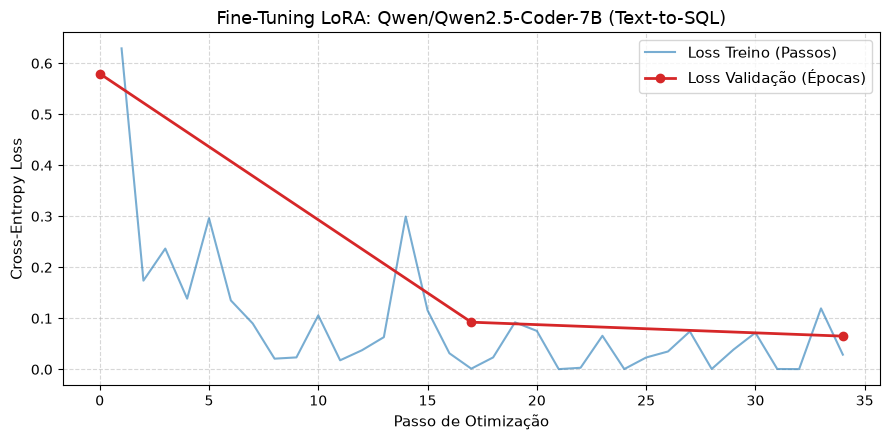

In [10]:
plt.figure(figsize=(9, 4.5))
plt.plot(hist_passo, hist_loss, label="Loss Treino (Passos)", color="#1f77b4", alpha=0.6)
plt.plot(hist_val_passo, hist_val, "o-", label="Loss Validação (Épocas)", color="#d62728", linewidth=2)
plt.title(f"Fine-Tuning LoRA: {MODELO_ID} (Text-to-SQL)", fontsize=13)
plt.xlabel("Passo de Otimização", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig("curva_loss_sql.png", dpi=150)
plt.show()


## 9. Avaliação Pós-Treino e Placar Comparativo (Antes vs. Depois)

Reavaliamos o modelo treinado sobre as mesmas tarefas de teste e geramos a tabela comparativa de **Execution Accuracy**.


In [11]:
# Avalia o modelo com os adaptadores LoRA ajustados
resultados_treinado = avaliar_modelo(model, tokenizer, exemplos_teste, nome_fase="MODELO TREINADO (LoRA)")

# Placar Comparativo
tabela_comparacao = []
for rotulo, lista in [("Variação (Intra-Distribuição)", "variacao"), ("Inédita (Zero-Shot)", "inedita")]:
    b_sub = [r for r in resultados_base if r["tipo"] == lista]
    t_sub = [r for r in resultados_treinado if r["tipo"] == lista]

    tx_base = sum(1 for r in b_sub if r["passou"]) / len(b_sub) if b_sub else 0
    tx_treinado = sum(1 for r in t_sub if r["passou"]) / len(t_sub) if t_sub else 0
    delta = (tx_treinado - tx_base) * 100

    tabela_comparacao.append([rotulo, f"{tx_base:.1%}", f"{tx_treinado:.1%}", f"{delta:+.1f}%"])

tot_base = sum(1 for r in resultados_base if r["passou"]) / len(resultados_base)
tot_treinado = sum(1 for r in resultados_treinado if r["passou"]) / len(resultados_treinado)
delta_tot = (tot_treinado - tot_base) * 100
tabela_comparacao.append(["TOTAL GERAL", f"{tot_base:.1%}", f"{tot_treinado:.1%}", f"{delta_tot:+.1f}%"])

print("\n" + "=" * 65)
print("🏆 PLACAR FINAL: EXECUTION ACCURACY NO SQLITE (pass@1)")
print("=" * 65)
print(tabulate(tabela_comparacao, headers=["Categoria de Teste", "Antes (Base)", "Depois (LoRA)", "Ganho"], tablefmt="fancy_grid"))



Iniciando avaliação [MODELO TREINADO (LoRA)] em 49 tarefas...
Avaliação concluída em 94.8 segundos.          
  - Variacao  : 27/33 (81.8%)
  - Inedita   :  7/16 (43.8%)
  * TOTAL     : 34/49 (69.4%)

🏆 PLACAR FINAL: EXECUTION ACCURACY NO SQLITE (pass@1)
╒═══════════════════════════════╤════════════════╤═════════════════╤═════════╕
│ Categoria de Teste            │ Antes (Base)   │ Depois (LoRA)   │ Ganho   │
╞═══════════════════════════════╪════════════════╪═════════════════╪═════════╡
│ Variação (Intra-Distribuição) │ 27.3%          │ 81.8%           │ +54.5%  │
├───────────────────────────────┼────────────────┼─────────────────┼─────────┤
│ Inédita (Zero-Shot)           │ 25.0%          │ 43.8%           │ +18.8%  │
├───────────────────────────────┼────────────────┼─────────────────┼─────────┤
│ TOTAL GERAL                   │ 26.5%          │ 69.4%           │ +42.9%  │
╘═══════════════════════════════╧════════════════╧═════════════════╧═════════╛


## 10. Visualização do Banco de dados fictício

In [15]:
# Cria a conexão com o banco SQLite em memória
conn = criar_banco_dados()

# Dicionario com os nomes das tabelas do nosso e-commerce
tabelas = ["clientes", "produtos", "pedidos", "itens_pedido"]

print("📊 VISUALIZAÇÃO DO BANCO DE DADOS EM DATAFRAMES\n" + "="*50)

for tabela in tabelas:
    # Carrega a tabela inteira para um DataFrame do pandas
    df = pd.read_sql(f"SELECT * FROM {tabela}", conn)
    
    print(f"\nTabela [{tabela}] ({len(df)} registros)")
    display(df) # Exibe o DataFrame formatado de forma bonita no Jupyter Notebook

# Fecha a conexão com o banco
conn.close()

📊 VISUALIZAÇÃO DO BANCO DE DADOS EM DATAFRAMES

Tabela [clientes] (8 registros)


,id,nome,cidade,estado,idade,data_cadastro
0,1,Ana Silva,São Paulo,SP,28,2023-01-15
1,2,Bruno Santos,Campinas,SP,35,2023-02-10
2,3,Carla Oliveira,Rio de Janeiro,RJ,42,2023-03-05
3,4,Diego Ferreira,Belo Horizonte,MG,23,2023-04-12
4,5,Eduarda Lima,Curitiba,PR,31,2023-05-20
5,6,Felipe Rocha,São Paulo,SP,45,2023-06-18
6,7,Gabriela Souza,Niterói,RJ,29,2023-07-22
7,8,Henrique Alves,Uberlândia,MG,38,2023-08-30



Tabela [produtos] (10 registros)


,id,nome,categoria,preco,estoque
0,1,Notebook Pro,Eletronicos,4500.0,15
1,2,Mouse Sem Fio,Eletronicos,120.0,50
2,3,Teclado Mecânico,Eletronicos,350.0,30
3,4,Monitor 27 Pol,Eletronicos,1800.0,8
4,5,Cadeira Gamer,Moveis,1200.0,12
5,6,Mesa Escritório,Moveis,850.0,5
6,7,Livro Python Fluente,Livros,130.0,40
7,8,Livro Clean Code,Livros,95.0,25
8,9,Headset Bluetooth,Eletronicos,290.0,20
9,10,Luminária LED,Moveis,75.0,60



Tabela [pedidos] (8 registros)


,id,cliente_id,data_pedido,valor_total,status
0,101,1,2023-09-01,4620.0,concluido
1,102,1,2023-09-15,350.0,concluido
2,103,2,2023-09-18,1200.0,concluido
3,104,3,2023-09-20,225.0,concluido
4,105,4,2023-09-22,1800.0,pendente
5,106,5,2023-09-25,130.0,cancelado
6,107,6,2023-09-28,4970.0,concluido
7,108,7,2023-10-02,850.0,pendente



Tabela [itens_pedido] (12 registros)


,id,pedido_id,produto_id,quantidade,preco_unitario
0,1,101,1,1,4500.0
1,2,101,2,1,120.0
2,3,102,3,1,350.0
3,4,103,5,1,1200.0
4,5,104,7,1,130.0
5,6,104,8,1,95.0
6,7,105,4,1,1800.0
7,8,106,7,1,130.0
8,9,107,1,1,4500.0
9,10,107,3,1,350.0


## 11. Testando respostas do modelo Text-to-SQL

Agora você pode testar qualquer consulta em português em tempo real! A função abaixo:
1. Envia sua pergunta para o modelo com o esquema do banco de dados;
2. Gera a consulta SQL;
3. Executa a query no SQLite em memória;
4. Renderiza os dados retornados em uma tabela formatada.


In [16]:
def perguntar_sql(pergunta):
    """Converte pergunta em linguagem natural para SQL e executa no banco de dados."""
    prompt = formatar_prompt(pergunta)
    entrada = tokenizer(prompt, return_tensors="pt").to(device)

    model.eval()
    with torch.no_grad():
        saida = model.generate(
            **entrada,
            max_new_tokens=80,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    tokens = saida[0][entrada["input_ids"].shape[1]:]
    sql = extrair_sql(tokenizer.decode(tokens, skip_special_tokens=True))

    print(f"\n{'='*70}")
    print(f"🗣️  Pergunta:  {pergunta}")
    print(f"⚡  SQL Gerado: \033[1;34m{sql}\033[0m")
    print(f"{'='*70}")

    conn = criar_banco_dados()
    try:
        cur = conn.cursor()
        cur.execute(sql)
        linhas = cur.fetchall()
        nomes_colunas = [desc[0] for desc in cur.description] if cur.description else []
        print(f"📊 Resultado retornado ({len(linhas)} linhas):")
        if linhas:
            print(tabulate(linhas, headers=nomes_colunas, tablefmt="rounded_grid"))
        else:
            print("(Nenhum registro encontrado)")
    except Exception as e:
        print(f"❌ Erro ao executar SQL no SQLite: {e}")

# Exemplos de teste ao vivo
perguntar_sql("Quais clientes moram no estado de SP?")
perguntar_sql("Mostre os 3 produtos mais caros da loja.")
perguntar_sql("Qual é a média de preço dos produtos da categoria Móveis?")
perguntar_sql("Liste o id do pedido e o nome do cliente para pedidos concluídos.")
# Exemplos de teste ao vivo testando o vocabulário corporativo e mapeamentos semânticos
print("\n--- 1. Testando Mapeamento Geográfico (Nome -> Sigla) ---")
perguntar_sql("Quais são os clientes que moram em São Paulo?")

print("\n--- 2. Testando Convenção de Sistema (Com Acento -> Sem Acento) ---")
perguntar_sql("Mostre o nome e o preço de todos os produtos da linha de Eletrônicos.")

print("\n--- 3. Testando Conceitos de Negócio e Faixas de Preço ---")
perguntar_sql("Liste o nome e preço dos produtos considerados de linha premium.")

print("\n--- 4. Testando Jargão Financeiro/ERP (Termo Comercial -> Status Interno) ---")
perguntar_sql("Quantos pedidos estão faturados e pagos?")

print("\n--- 5. Testando Regras de Logística e Estoque ---")
perguntar_sql("Quais produtos estão em nível crítico de ruptura?")

print("\n--- 6. Testando Tarefa Inédita / Composicional (Filtro Cruzado Complexo) ---")
perguntar_sql("Qual a soma do valor total dos pedidos faturados e pagos feitos por clientes do estado de Rio de Janeiro?")



🗣️  Pergunta:  Quais clientes moram no estado de SP?
⚡  SQL Gerado: SELECT nome FROM clientes WHERE estado = 'SP';
📊 Resultado retornado (3 linhas):
╭──────────────╮
│ nome         │
├──────────────┤
│ Ana Silva    │
├──────────────┤
│ Bruno Santos │
├──────────────┤
│ Felipe Rocha │
╰──────────────╯

🗣️  Pergunta:  Mostre os 3 produtos mais caros da loja.
⚡  SQL Gerado: SELECT nome, preco FROM produtos ORDER BY preco DESC LIMIT 3;
📊 Resultado retornado (3 linhas):
╭────────────────┬─────────╮
│ nome           │   preco │
├────────────────┼─────────┤
│ Notebook Pro   │    4500 │
├────────────────┼─────────┤
│ Monitor 27 Pol │    1800 │
├────────────────┼─────────┤
│ Cadeira Gamer  │    1200 │
╰────────────────┴─────────╯

🗣️  Pergunta:  Qual é a média de preço dos produtos da categoria Móveis?
⚡  SQL Gerado: SELECT AVG(preco) FROM produtos WHERE categoria = 'Moveis';
📊 Resultado retornado (1 linhas):
╭──────────────╮
│   AVG(preco) │
├──────────────┤
│      708.333 │
╰──────────────╯


In [25]:
import gradio as gr
import sqlite3
import pandas as pd
import torch

def chatbot_text_to_sql(mensagem_usuario, historico, arquivo_db):
    """Função principal que processa o chat, gera o SQL e consulta o banco de dados."""
    if not mensagem_usuario.strip():
        return "Por favor, digite uma pergunta válida."

    # 1. Conecta ao banco de dados fornecido por upload ou usa o em memória padrão
    try:
        if arquivo_db is None:
            conn = criar_banco_dados()
            db_info = "Banco SQLite em Memória (Padrão do E-Commerce)"
        else:
            caminho = arquivo_db.name if hasattr(arquivo_db, "name") else arquivo_db
            conn = sqlite3.connect(caminho)
            db_info = f"Banco personalizado carregado com sucesso"
    except Exception as e:
        return f"❌ Erro ao conectar ao banco de dados: {e}"

    try:
        prompt = formatar_prompt(mensagem_usuario)
        entrada = tokenizer(prompt, return_tensors="pt").to(device)

        model.eval()
        with torch.no_grad():
            saida = model.generate(
                **entrada,
                max_new_tokens=100,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )

        tokens = saida[0][entrada["input_ids"].shape[1]:]
        sql_gerado = extrair_sql(tokenizer.decode(tokens, skip_special_tokens=True))

        cur = conn.cursor()
        cur.execute(sql_gerado)
        linhas = cur.fetchall()
        nomes_colunas = [desc[0] for desc in cur.description] if cur.description else []

        resposta_md = f"⚙️ **Fonte:** {db_info}\n\n"
        resposta_md += f"⚡ **SQL Gerado:**\n```sql\n{sql_gerado}\n```\n\n"
        
        if linhas:
            df_resultado = pd.DataFrame(linhas, columns=nomes_colunas)
            resposta_md += f"📊 **Resultados ({len(linhas)} registos):**\n\n"
            resposta_md += df_resultado.to_markdown(index=False)
        else:
            resposta_md += "📊 **Resultados:** Nenhum registo encontrado."

        return resposta_md

    except Exception as e:
        return f"❌ **Erro ao executar a consulta SQL:**\n```sql\n{sql_gerado if 'sql_gerado' in locals() else 'N/A'}\n```\n**Detalhes:** {e}"
    finally:
        conn.close()


def renderizar_tabelas_html(arquivo_db):
    """Lê todas as tabelas e cria uma grade (Grid) HTML com CSS forçando alto contraste."""
    try:
        if arquivo_db is None:
            conn = criar_banco_dados()
        else:
            caminho = arquivo_db.name if hasattr(arquivo_db, "name") else arquivo_db
            conn = sqlite3.connect(caminho)
        
        cursor = conn.cursor()
        cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
        tabelas = [t[0] for t in cursor.fetchall() if t[0] != 'sqlite_sequence']
        
        if not tabelas:
            return "<i>Nenhuma tabela encontrada neste banco de dados.</i>"

        # Injeção de CSS para garantir alto contraste (texto escuro sobre fundo claro) mesmo em Dark Mode
        html_output = "<style>"
        html_output += ".db-card { border: 1px solid #e0e0e0; border-radius: 8px; padding: 15px; background-color: #ffffff !important; color: #111827 !important; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.1); }"
        html_output += ".db-card h3 { margin-top: 0; color: #1f2937 !important; text-align: center; border-bottom: 2px solid #3b82f6; padding-bottom: 8px; font-family: sans-serif; }"
        html_output += ".db-table { width: 100%; border-collapse: collapse; font-size: 0.9em; font-family: sans-serif; text-align: center; }"
        html_output += ".db-table thead th { background-color: #f3f4f6 !important; color: #111827 !important; font-weight: bold; padding: 10px; border: 1px solid #d1d5db; position: sticky; top: 0; }"
        html_output += ".db-table tbody td { padding: 8px; border: 1px solid #e5e7eb; color: #374151 !important; }"
        html_output += ".db-table tbody tr:nth-child(even) { background-color: #f9fafb !important; }"
        html_output += "</style>"

        # CSS Grid para alinhar as tabelas lado a lado
        html_output += "<div style='display: grid; grid-template-columns: repeat(auto-fit, minmax(350px, 1fr)); gap: 20px;'>"
        
        for tab in tabelas:
            df = pd.read_sql(f"SELECT * FROM {tab}", conn)
            
            html_output += "<div class='db-card'>"
            html_output += f"<h3>📦 {tab} <span style='font-size: 0.8em; color: #6b7280 !important;'>({len(df)} registros)</span></h3>"
            
            html_output += f"<div style='max-height: 300px; overflow: auto;'>"
            # O parâmetro classes injecta as nossas regras CSS diretamente na tabela gerada pelo pandas
            html_output += df.to_html(index=False, classes='db-table', border=0)
            html_output += "</div></div>"
            
        html_output += "</div>"
            
        conn.close()
        return html_output
    except Exception as e:
        return f"<b style='color:red;'>Erro ao carregar tabelas: {str(e)}</b>"


# Construção do layout
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# Chatbot Interativo Text-to-SQL")
    gr.Markdown("Faça perguntas em linguagem natural, teste o assistente inteligente e visualize as tabelas do seu banco na parte inferior da tela.")

    # 1. Seção de Conexão no Topo
    with gr.Row():
        input_file = gr.File(
            label="1. Carregue seu próprio Banco SQLite (.db / .sqlite) [Deixe em branco para usar o banco Padrão de E-Commerce]",
            file_types=[".db", ".sqlite", ".sqlite3"],
            type="filepath"
        )
            
    gr.Markdown("---")
    
    # 2. Seção do Chatbot (Onde o usuário interage)
    gr.Markdown("### 2. Chat: Pergunte em Linguagem Natural")
    chat_interface = gr.ChatInterface(
        fn=chatbot_text_to_sql,
        additional_inputs=[input_file],
        title="",
        description="Escreva a sua dúvida comercial abaixo ou escolha um dos exemplos:",
        submit_btn="Enviar Pergunta",
        examples=[
            ["Quais são os clientes que moram em São Paulo?", None],
            ["Mostre o nome e o preço de todos os produtos da linha de Eletrônicos.", None],
            ["Quantos pedidos estão faturados e pagos?", None],
            ["Liste o nome e preço dos produtos considerados de linha premium.", None],
            ["Qual a soma do valor total dos pedidos faturados e pagos feitos por clientes do estado de Rio de Janeiro?", None]
        ]
    )

    gr.Markdown("---")

    # 3. Seção do Inspetor de Banco (Tabelas lado a lado abaixo do chat)
    gr.Markdown("### 3. Dicionário de Dados: Consulte suas tabelas para criar prompts que te interessem")
    gr.Markdown("*Clique no botão abaixo para carregar e inspecionar a estrutura e os dados de todas as tabelas conectadas.*")
    
    btn_atualizar = gr.Button("🔄 Mostrar / Atualizar Tabelas do Banco", variant="primary")
    
    tabelas_html = gr.HTML(
        value="<div style='padding: 20px; border: 1px dashed #888; text-align: center; color: #888; background-color: transparent;'><i>Nenhum dado carregado. Clique no botão azul acima para visualizar.</i></div>"
    )

    # Evento para processar a exibição HTML da grade de tabelas
    btn_atualizar.click(fn=renderizar_tabelas_html, inputs=[input_file], outputs=[tabelas_html])

# Lança a aplicação no Jupyter
demo.launch(inline=True, share=False)

/var/folders/n6/y4cj9wc929j5kd6f79qz9xb40000gn/T/ipykernel_54560/3279259266.py:111: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


* Running on local URL:  http://127.0.0.1:7866
* To create a public link, set `share=True` in `launch()`.
